In [1]:
#Importancion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#Crear el dataframe
path= "../data/abalone.csv"
df=pd.read_csv(path)
display(df.head(10))


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7
5,I,0.425,0.300,0.095,0.3515,0.1410,0.0775,0.120,8
6,F,0.530,0.415,0.150,0.7775,0.2370,0.1415,0.330,20
7,F,0.545,0.425,0.125,0.7680,0.2940,0.1495,0.260,16
8,M,0.475,0.370,0.125,0.5095,0.2165,0.1125,0.165,9
9,F,0.550,0.440,0.150,0.8945,0.3145,0.1510,0.320,19


In [5]:
df.corr()

C:\Users\Ivan galeno reyes\AppData\Local\Temp\ipykernel_11068\1134722465.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()


,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
Length,1.000000,0.986812,0.827554,0.925261,0.897914,0.903018,0.897706,0.556720
Diameter,0.986812,1.000000,0.833684,0.925452,0.893162,0.899724,0.905330,0.574660
Height,0.827554,0.833684,1.000000,0.819221,0.774972,0.798319,0.817338,0.557467
Whole_weight,0.925261,0.925452,0.819221,1.000000,0.969405,0.966375,0.955355,0.540390
Shucked_weight,0.897914,0.893162,0.774972,0.969405,1.000000,0.931961,0.882617,0.420884
Viscera_weight,0.903018,0.899724,0.798319,0.966375,0.931961,1.000000,0.907656,0.503819
Shell_weight,0.897706,0.905330,0.817338,0.955355,0.882617,0.907656,1.000000,0.627574
Rings,0.556720,0.574660,0.557467,0.540390,0.420884,0.503819,0.627574,1.000000


<Axes: xlabel='Length', ylabel='Diameter'>

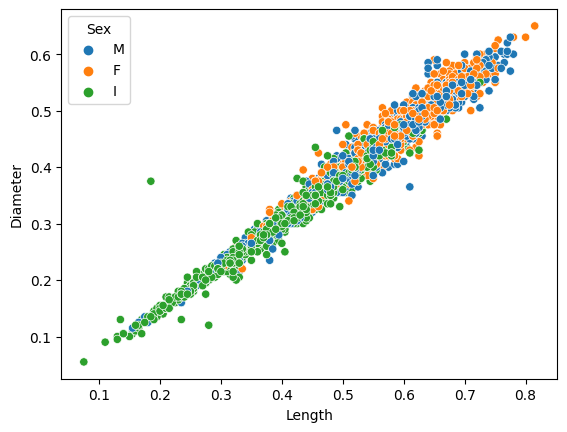

In [8]:
sns.scatterplot(x=df["Length"], y=df["Diameter"], hue=df["Sex"])

In [9]:
#Hipotesis: La variable que se nos pide predecir es la Glucosa a partir de una variable explicativa
y = df["Diameter"]
print(y.shape)
display(y.head(10))

(4177,)


0    0.365
1    0.265
2    0.420
3    0.365
4    0.255
5    0.300
6    0.415
7    0.425
8    0.370
9    0.440
Name: Diameter, dtype: float64

In [10]:
#Definir variable explicativa
X = df[["Length"]]
print(X.shape)
display(X.head(10))

(4177, 1)


,Length
0,0.455
1,0.350
2,0.530
3,0.440
4,0.330
5,0.425
6,0.530
7,0.545
8,0.475
9,0.550


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split       
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [12]:
X_train, X_test, y_train, y_test =train_test_split(X,y,random_state=42, test_size=0.2)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(3341, 1)
(836, 1)
(3341,)
(836,)


In [13]:
y_train.head(10)

4038    0.445
1272    0.355
3384    0.225
3160    0.200
3894    0.380
1288    0.380
3863    0.500
554     0.390
1871    0.430
1074    0.300
Name: Diameter, dtype: float64

In [14]:
model = LinearRegression()
#model.fit(X,y)                   #Posible sobreajuste
model.fit(X_train, y_train)       #Entrenamiento del modelo

LinearRegression()

In [15]:
#Generar predicciones para "evaluar" el modelo
y_pred = model.predict(X_test)
print(y_pred.shape)
y_pred

(836,)


array([0.47397549, 0.4617078 , 0.43717241, 0.49851089, 0.36765546,
       0.40445855, 0.40445855, 0.37174469, 0.27769236, 0.45761857,
       0.45761857, 0.27360313, 0.37174469, 0.27769236, 0.38401239,
       0.44126164, 0.45352933, 0.42899394, 0.5516709 , 0.38810162,
       0.57211706, 0.55576013, 0.48624319, 0.49033242, 0.46579703,
       0.33494161, 0.40445855, 0.40036932, 0.4494401 , 0.39628009,
       0.39628009, 0.49033242, 0.27769236, 0.38810162, 0.38401239,
       0.4494401 , 0.22453234, 0.06914153, 0.36356623, 0.24906774,
       0.56802783, 0.55984937, 0.49851089, 0.41263701, 0.44126164,
       0.56802783, 0.43308317, 0.45352933, 0.40854778, 0.11821231,
       0.26542466, 0.50260012, 0.40445855, 0.12230155, 0.30222775,
       0.41672625, 0.46988626, 0.52713551, 0.45352933, 0.26542466,
       0.47397549, 0.52713551, 0.48215396, 0.30222775, 0.35129854,
       0.52304628, 0.16319386, 0.27769236, 0.40036932, 0.41672625,
       0.51486781, 0.39219085, 0.31858468, 0.34312007, 0.31449

In [16]:
#Medir la precision del modelo
r2= r2_score(y_pred, y_test)
mae= mean_absolute_error(y_pred, y_test)
mse=mean_squared_error(y_pred, y_test)

print(f"r2: {r2:.4f}, mae: {mae:.4f}, mse: {mse:.4f}")

r2: 0.9698, mae: 0.0117, mse: 0.0003


In [17]:
#Definir ecuacion de regresion lineal
print(model.coef_)            #el valor de m
print(model.intercept_)       #el valor de b

[0.81784639]
-0.02082157371399196
